# MD Analysis

Test that packages are correctly loaded.

In [1]:
import MDAnalysis as mda
from MDAnalysis.tests.datafiles import PSF, DCD, GRO, XTC

import warnings
# suppress some MDAnalysis warnings about PSF files
warnings.filterwarnings('ignore')

from matplotlib import pyplot as plt

print(mda.Universe(PSF, DCD))
print("Using MDAnalysis version", mda.__version__)

%matplotlib inline

<Universe with 3341 atoms>
Using MDAnalysis version 2.9.0


## 1. Load structure and trajectory

In [2]:
datadir = '../../data/1bf5/wt/rep1/gromacs'

In [3]:
! ls $datadir

em.edr				  md.trr	     output_16x8_2.log
em.gro				  md.xtc	     output_2x64.log
em.log				  minim.mdp	     output_4x32.log
em.tpr				  npt.cpt	     step11b_n9.pdb
em.trr				  npt.edr	     step11c_n9.pdb
index.ndx			  npt.gro	     step19b_n13.pdb
ions.mdp			  npt.log	     step19c_n13.pdb
md.cpt				  npt.mdp	     step21b_n13.pdb
md.edr				  npt.tpr	     step21c_n13.pdb
md.gro				  npt.trr	     step27b_n13.pdb
md.log				  nvt.cpt	     step27c_n13.pdb
md.mdp				  nvt.edr	     step31b_n13.pdb
md_noPBC_mol_com_cluster_fit.xtc  nvt.gro	     step31c_n13.pdb
mdout.mdp			  nvt.log	     step41b_n13.pdb
md_prev.cpt			  nvt.mdp	     step41c_n13.pdb
md_prot.pdb			  nvt.tpr	     step42b_n13.pdb
md_sys.pdb			  nvt.trr	     step42c_n13.pdb
md.tpr				  output_16x8_1.log


In [4]:
# Initialize universe
u = mda.Universe(f'{datadir}/md_sys.pdb',f'{datadir}/md_noPBC_mol_com_cluster_fit.xtc')

In [5]:
print(u)
print('Number of frames in the trajectory: ', len(u.trajectory))
print('Number of residues: ', len(u.residues))
print(u.residues)
print('Number of atoms: ', len(u.atoms))
print(u.atoms)
print('Segments: ', u.segments)

<Universe with 437133 atoms>
Number of frames in the trajectory:  2001
Number of residues:  105932
<ResidueGroup [<Residue LEU, 1>, <Residue ASP, 2>, <Residue LYS, 3>, ..., <Residue Cl, 105309>, <Residue Cl, 105310>, <Residue Cl, 105311>]>
Number of atoms:  437133
<AtomGroup [<Atom 1: N of type N of resname LEU, resid 1 and segid A and altLoc >, <Atom 2: H1 of type H of resname LEU, resid 1 and segid A and altLoc >, <Atom 3: H2 of type H of resname LEU, resid 1 and segid A and altLoc >, ..., <Atom 437131: Cl of type Cl of resname Cl, resid 105309 and segid  and altLoc >, <Atom 437132: Cl of type Cl of resname Cl, resid 105310 and segid  and altLoc >, <Atom 437133: Cl of type Cl of resname Cl, resid 105311 and segid  and altLoc >]>
Segments:  <SegmentGroup [<Segment A>, <Segment B>, <Segment C>, <Segment D>, <Segment >]>


In [6]:
print(u.trajectory.frame)

0


### 1.1. Define components (and domains) as segments

In [7]:
# Select atoms by chain
dimer = u.select_atoms("segid A B")  # Assuming dimer spans chains A and B
monoA = u.select_atoms("segid A")    # Monomer A is chain A
monoB = u.select_atoms("segid B")    # Monomer B is chain B
dna = u.select_atoms("segid C D")    # Assuming dsDNA spans chains C and D
dnaC = u.select_atoms("segid C")     # DNA chain A is chain C
dnaD = u.select_atoms("segid D")     # DNA chain B is chain D

# Store selections in a list for easy iteration
selections = [
    ("Dimer", dimer, "A, B"),
    ("Monomer A", monoA, "A"),
    ("Monomer B", monoB, "B"),
    ("dsDNA", dna, "C, D"),
    ("DNA A", dnaC, "C"),
    ("DNA B", dnaD, "D")
]

# Print atom group name, chain, and atom index range
for name, group, chain in selections:
    atom_indices = group.atoms.indices
    index_range = f"{min(atom_indices)}:{max(atom_indices)}"
    print(f"{name}: Chain(s) {chain}, Atom Index Range {index_range}, Residues {len(group.residues)}")

Dimer: Chain(s) A, B, Atom Index Range 0:18825, Residues 1150
Monomer A: Chain(s) A, Atom Index Range 0:9412, Residues 575
Monomer B: Chain(s) B, Atom Index Range 9413:18825, Residues 575
dsDNA: Chain(s) C, D, Atom Index Range 18826:20282, Residues 46
DNA A: Chain(s) C, Atom Index Range 18826:19552, Residues 23
DNA B: Chain(s) D, Atom Index Range 19553:20282, Residues 23


## 2. QC

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
from MDAnalysis.analysis import rms, align

### 2.1. RMSD

In [15]:
u.trajectory[0] # set to first frame
rmsd_analysis = rms.RMSD(u, select='backbone', groupselections=['name CA', 'protein'])
rmsd_analysis.run()

In [16]:
print(rmsd_analysis.results.rmsd.shape)

(2001, 5)


(From MDAnalysis docs)
Each row is the RMSD associated with a frame in the trajectory. The columns are as follows:

1. Frame number

2. Time (ps)

3. RMSD (backbone)

4. RMSD (C-alpha)

5. RMSD (protein)


In [17]:
rmsd_df = pd.DataFrame(rmsd_analysis.results.rmsd[:, 2:],
                       columns=['Backbone', 'C-alphas', 'Protein'],
                       index=rmsd_analysis.results.rmsd[:, 1])
rmsd_df.index.name = 'Time (ps)'
rmsd_df.head()

,Backbone,C-alphas,Protein
Time (ps),,,
0.0,9.006978e-07,5.206398e-07,4.779483e-07
100.0,1.157570e+00,1.149319e+00,1.499914e+00
200.0,1.463379e+00,1.452034e+00,1.844372e+00
300.0,1.661011e+00,1.650900e+00,2.066034e+00
400.0,1.732828e+00,1.719224e+00,2.146052e+00


Text(0, 0.5, 'RMSD (Å)')

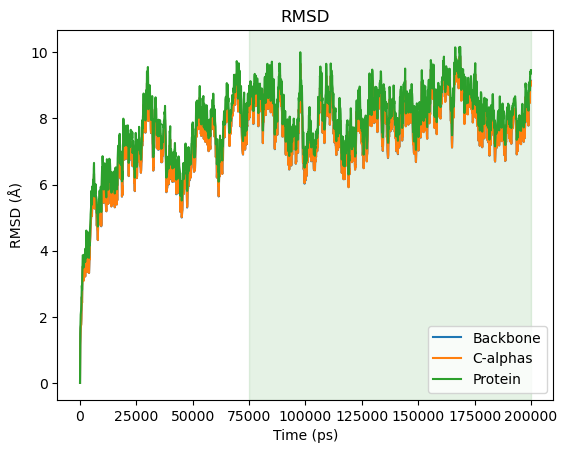

In [18]:
rmsd_df.plot(title='RMSD')
plt.axvspan(75000, 200000, zorder=0, alpha=0.1, color='green', label='Stable region')

plt.ylabel('RMSD (Å)')

In [19]:
rmsd_df_bb = pd.DataFrame(rmsd_analysis.results.rmsd[:, 2],
                       columns=['Backbone'],
                       index=rmsd_analysis.results.rmsd[:, 1])
rmsd_df_bb.index.name = 'Time (ps)'

rmsd_df_ca = pd.DataFrame(rmsd_analysis.results.rmsd[:, 3],
                       columns=['Backbone'],
                       index=rmsd_analysis.results.rmsd[:, 1])
rmsd_df_ca.index.name = 'Time (ps)'

rmsd_df_prot = pd.DataFrame(rmsd_analysis.results.rmsd[:, 4],
                       columns=['Backbone'],
                       index=rmsd_analysis.results.rmsd[:, 1])
rmsd_df_prot.index.name = 'Time (ps)'

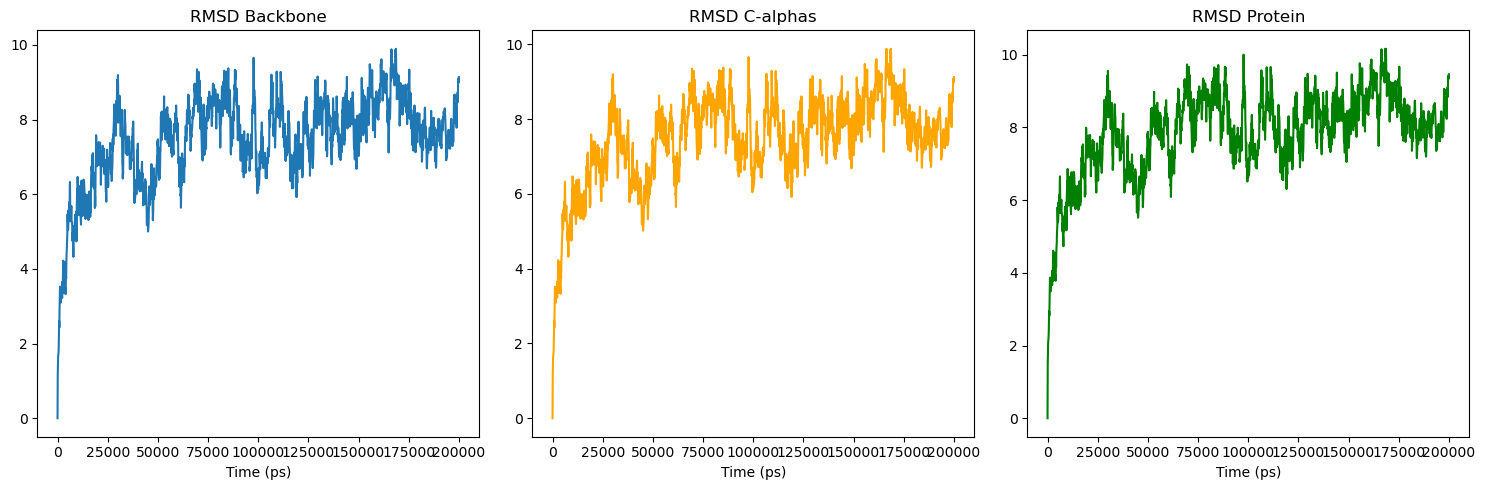

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))  # 1 row, 3 columns

rmsd_df_bb.plot(title='RMSD Backbone', ax=axes[0], legend=False)
rmsd_df_ca.plot(title='RMSD C-alphas', ax=axes[1], legend=False, c='orange')
rmsd_df_prot.plot(title='RMSD Protein', ax=axes[2], legend=False, c='green')

plt.tight_layout()
plt.show()

Text(0, 0.5, 'RMSD (Å)')

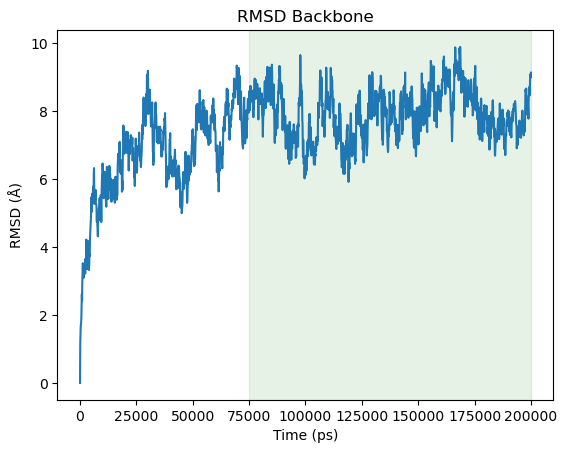

In [21]:
rmsd_df_bb.plot(title='RMSD Backbone', legend=False)
plt.axvspan(75000, 200000, zorder=0, alpha=0.1, color='green', label='Stable region')

plt.ylabel('RMSD (Å)')

**Radius of gyration**

In [22]:
def radgyr(atomgroup, masses, total_mass=None):
    # coordinates change for each frame
    coordinates = atomgroup.positions
    center_of_mass = atomgroup.center_of_mass()

    # get squared distance from center
    ri_sq = (coordinates-center_of_mass)**2
    # sum the unweighted positions
    sq = np.sum(ri_sq, axis=1)
    sq_x = np.sum(ri_sq[:,[1,2]], axis=1) # sum over y and z
    sq_y = np.sum(ri_sq[:,[0,2]], axis=1) # sum over x and z
    sq_z = np.sum(ri_sq[:,[0,1]], axis=1) # sum over x and y

    # make into array
    sq_rs = np.array([sq, sq_x, sq_y, sq_z])

    # weight positions
    rog_sq = np.sum(masses*sq_rs, axis=1)/total_mass
    # square root and return
    return np.sqrt(rog_sq)

In [23]:
result = []
for frame in u.trajectory:
    result.append(radgyr(atomgroup=dimer,
                         masses=dimer.masses,
                         total_mass=np.sum(dimer.masses)))

Text(0.5, 0, 'Frame')

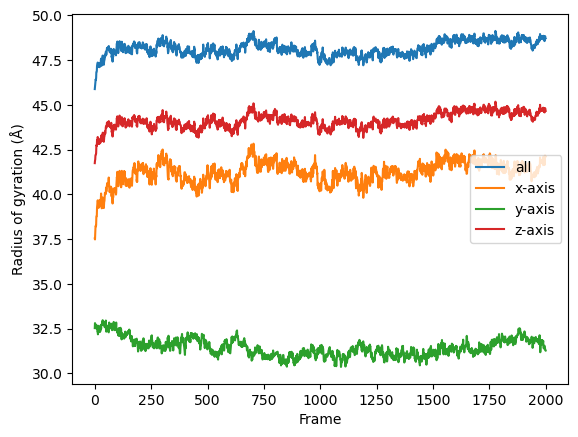

In [24]:
result = np.asarray(result).T

labels = ['all', 'x-axis', 'y-axis', 'z-axis']
for col, label in zip(result, labels):
    plt.plot(col, label=label)
plt.legend()
plt.ylabel('Radius of gyration (Å)')
plt.xlabel('Frame')

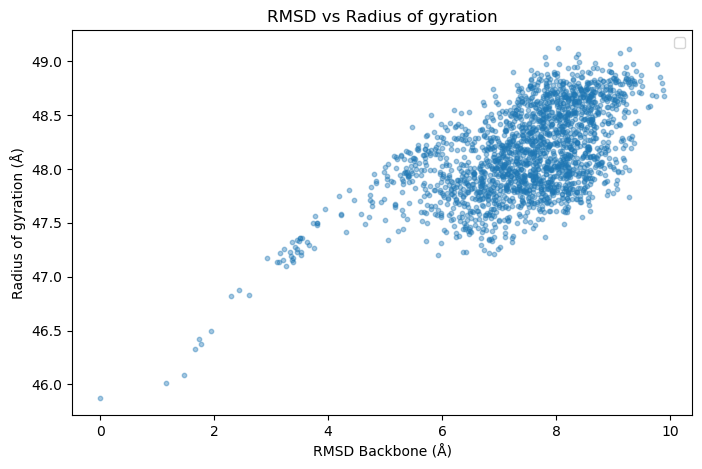

In [25]:
plt.figure(figsize=(8, 5))
plt.scatter(rmsd_analysis.results.rmsd[:, 2], result[0,:],s=10, alpha=0.4)
plt.xlabel("RMSD Backbone (Å)")
plt.ylabel("Radius of gyration (Å)")
plt.title("RMSD vs Radius of gyration")
plt.legend()
plt.show()

### 2.2. RMSF

In [ ]:
nonsol = u.select_atoms("segid A B C D")

In [9]:
average = align.AverageStructure(u, u, select='protein and name CA',
                                 ref_frame=0).run()
ref = average.results.universe

In [10]:
aligner = align.AlignTraj(u, ref,
                          select='protein and name CA',
                          in_memory=False).run()

**Protein**

In [11]:
monoA_ca = monoA.select_atoms('name CA')
RA = rms.RMSF(monoA_ca).run()

monoB_ca = monoB.select_atoms('name CA')
RB = rms.RMSF(monoB_ca).run()

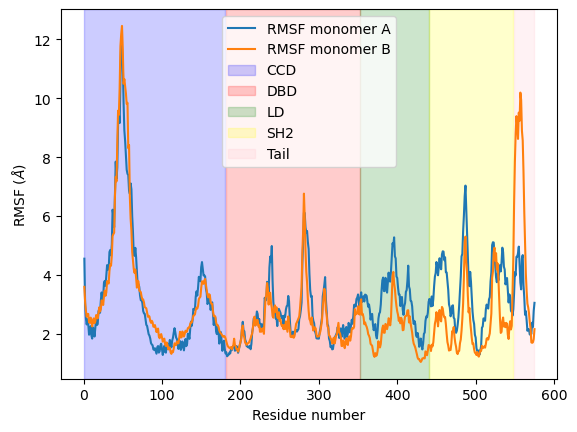

In [12]:
plt.plot(monoA_ca.resids, RA.results.rmsf, label='RMSF monomer A')
plt.plot(monoB_ca.resids, RB.results.rmsf, label='RMSF monomer B')

plt.axvspan(0, 180, zorder=0, alpha=0.2, color='blue', label='CCD')
plt.axvspan(181, 352, zorder=0, alpha=0.2, color='red', label='DBD')
plt.axvspan(353, 440, zorder=0, alpha=0.2, color='green', label='LD')
plt.axvspan(441, 548, zorder=0, alpha=0.2, color='yellow', label='SH2')
plt.axvspan(549, 574, zorder=0, alpha=0.2, color='pink', label='Tail')


plt.xlabel('Residue number')
plt.ylabel('RMSF ($\AA$)')
plt.legend()

**DNA**

In [13]:
dnaC_p = dnaC.select_atoms('name P')
RC = rms.RMSF(dnaC_p).run()

dnaD_p = dnaD.select_atoms('name P')
RD = rms.RMSF(dnaD_p).run()

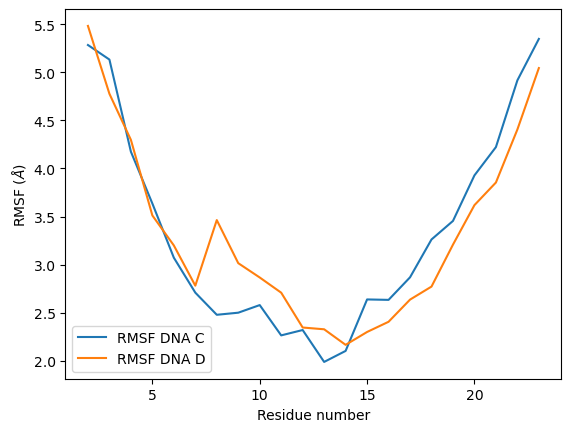

In [14]:
plt.plot(dnaC_p.resids, RC.results.rmsf, label='RMSF DNA C')
plt.plot(dnaD_p.resids, RD.results.rmsf, label='RMSF DNA D')

plt.xlabel('Residue number')
plt.ylabel('RMSF ($\AA$)')
plt.legend()

## 3. Analysis

### 3.1. Distances between two selections (DBD and DNA) STATIC

Options:

- Phosphorus Atom (P) - Best for Backbone Distances
- Sugar Ring Carbon (C1') - Best for Base-Specific Interactions
- Nitrogen Atoms in Bases (N1 for Pyrimidines, N9 for Purines) - Best for Direct Binding Sites
- OP2 - "Sticks out" of DNA

In [ ]:
from MDAnalysis.analysis import distances

**With P as reference atom for nucleotides:**

In [ ]:
monoA_ca = monoA.select_atoms('name CA')
monoB_ca = monoB.select_atoms('name CA')
dnaC_p = dnaC.select_atoms('name P')
dnaD_p = dnaD.select_atoms('name P')

print(len(monoA_ca.atoms))
print(len(monoB_ca.atoms))
print(len(dnaC_p.atoms))
print(len(dnaD_p.atoms))


In [ ]:
dist_arr_aa_p = distances.distance_array(monoA_ca.positions, # reference
                                    dnaC_p.positions, # configuration
                                    box=u.dimensions)
dist_arr_aa_p.shape

In [ ]:
fig, ax = plt.subplots()
im = ax.imshow(dist_arr_aa_p, origin='upper', aspect='auto')

# add residue ID labels to axes
tick_interval = 50
ax.set_yticks(np.arange(len(monoA_ca.atoms))[::tick_interval])
ax.set_xticks(np.arange(len(dnaC_p.atoms))[::4])
ax.set_yticklabels(monoA_ca.resids[::tick_interval])
ax.set_xticklabels(dnaC_p.resids[::4])

# add figure labels and titles
plt.ylabel('Monomer A')
plt.xlabel('DNA A')
plt.title('Distance between CA and P')

# colorbar
cbar = fig.colorbar(im)
cbar.ax.set_ylabel('Distance (Angstrom)')

In [ ]:
pairs = [
    (monoA_ca, dnaC_p, "Monomer A CA to DNA A P"),
    (monoB_ca, dnaC_p, "Monomer B CA to DNA A P"),
    (monoA_ca, dnaD_p, "Monomer A CA to DNA B P"),
    (monoB_ca, dnaD_p, "Monomer B CA to DNA B P")
]

num_frames = len(u.trajectory)
datasets = []

# Loop through trajectory and calculate distances for all pairs
for mono, dna, _ in pairs:
    resclose = []
    for ts in u.trajectory:
        dist_arr = distances.distance_array(mono.positions, dna.positions, box=u.dimensions)
        num_close_residues = np.sum(np.any(dist_arr < 5, axis=1))
        resclose.append(num_close_residues)
    datasets.append(resclose)

# Plot
y_min = min(min(data) for data in datasets)  
y_max = max(max(data) for data in datasets)

plt.figure(figsize=(16, 8)) 
for i, (data, (_, _, title)) in enumerate(zip(datasets, pairs), start=1):
    plt.subplot(2, 2, i)  # rows, cols, index
    plt.scatter(range(num_frames), data, label=title, s=10, alpha=0.5)
    plt.xlabel("Frame")
    plt.ylabel("Residues < 5 Å")
    plt.ylim(y_min, y_max+1) 
    plt.title(title)
    plt.legend()

plt.tight_layout()  
plt.show()


**With OP2 as reference atom for nucleotides:**

In [ ]:
monoA_ca = monoA.select_atoms('name CA')
monoB_ca = monoB.select_atoms('name CA')
dnaC_op2 = dnaC.select_atoms('name OP2')
dnaD_op2 = dnaD.select_atoms('name OP2')

print(len(monoA_ca.atoms))
print(len(monoB_ca.atoms))
print(len(dnaC_op2.atoms))
print(len(dnaD_op2.atoms))

In [ ]:
pairs = [
    (monoA_ca, dnaC_op2, "Monomer A CA to DNA A OP2"),
    (monoB_ca, dnaC_op2, "Monomer B CA to DNA A OP2"),
    (monoA_ca, dnaD_op2, "Monomer A CA to DNA B OP2"),
    (monoB_ca, dnaD_op2, "Monomer B CA to DNA B OP2")
]

num_frames = len(u.trajectory)
datasets = []

# Loop through trajectory and calculate distances for all pairs
for mono, dna, _ in pairs:
    resclose = []
    for ts in u.trajectory:
        dist_arr = distances.distance_array(mono.positions, dna.positions, box=u.dimensions)
        num_close_residues = np.sum(np.any(dist_arr < 5, axis=1))
        resclose.append(num_close_residues)
    datasets.append(resclose)

# Plot
y_min = min(min(data) for data in datasets)  
y_max = max(max(data) for data in datasets)

plt.figure(figsize=(16, 8)) 
for i, (data, (_, _, title)) in enumerate(zip(datasets, pairs), start=1):
    plt.subplot(2, 2, i)  # rows, cols, index
    plt.scatter(range(num_frames), data, label=title, s=10, alpha=0.5)
    plt.xlabel("Frame")
    plt.ylabel("Residues < 5 Å")
    plt.ylim(y_min, y_max+1) 
    plt.title(title)

plt.tight_layout()  
plt.show()

In [ ]:
residues_close_over_time = []  # List to store residue information per frame

for ts in u.trajectory:  # Loop through all frames
    # Compute distance array
    dist_arr = distances.distance_array(monoA_ca.positions,  
                                        dnaC_op2.positions,  
                                        box=u.dimensions)

    # Identify residues with at least one atom within 4 Å
    close_res_indices = np.any(dist_arr < 5, axis=1)  # Boolean mask for close atoms
    close_residues = monoA_ca[close_res_indices].residues  # Get the corresponding residues

    # Extract unique (resname, resid) pairs
    unique_residues = {(res.resname, res.resid) for res in close_residues}

    # Store the result for this frame
    residues_close_over_time.append(unique_residues)

unique_residues

**With C1' as reference atom for nucleotides:**

In [ ]:
dnaC_c1 = dnaC.select_atoms("name C1'")
dnaD_c1 = dnaD.select_atoms("name C1'")

print(len(dnaC_c1.atoms))
print(len(dnaD_c1.atoms))

In [ ]:
dist_arr_c1 = distances.distance_array(monoA_ca.positions, # reference
                                    dnaD_c1.positions, # configuration
                                    box=u.dimensions)
dist_arr_c1.shape

In [ ]:
fig, ax = plt.subplots()
im = ax.imshow(dist_arr_c1, origin='upper', aspect='auto')

# add residue ID labels to axes
tick_interval = 50
ax.set_yticks(np.arange(len(monoA_ca.atoms))[::tick_interval])
ax.set_xticks(np.arange(len(dnaD_c1.atoms))[::5])
ax.set_yticklabels(monoA_ca.resids[::tick_interval])
ax.set_xticklabels(dnaD_c1.resids[::5])

# add figure labels and titles
plt.ylabel('Monomer A')
plt.xlabel('DNA A')
plt.title("Distance between CA and DNA B C1'")

# colorbar
cbar = fig.colorbar(im)
cbar.ax.set_ylabel('Distance (Angstrom)')

In [ ]:
# Count residues where at least one distance is < 4 Å
close_residues = np.any(dist_arr_c1 < 5, axis=1)  # Boolean array
num_close_residues = np.sum(close_residues)  # Total count
print(f"Number of residues with distances < 5 Å: {num_close_residues}")

### 3.2. Hydrogen bonds

**GROMACS**

In [ ]:
ndx_file = f'{datadir}/hbonds_prot.ndx'

In [ ]:
# Lists to store hydrogen bond data
hbonds_data = []
current_frame = None

# Parse the .ndx file
with open(ndx_file, 'r') as f:
    lines = f.readlines()
    start_parsing = False
    
    for line in lines:
        line = line.strip()
        
        # Start parsing at [ hbonds_Protein_PTR-DNA_frame_0 ]
        if '[ hbonds_Protein_PTR-DNA_frame_0 ]' in line:
            start_parsing = True
            current_frame = 0
            continue
        
        # Stop parsing if we hit an unrelated section (optional, adjust if needed)
        if start_parsing and line.startswith('[') and 'hbonds_Protein_PTR-DNA_frame' not in line:
            break
        
        if start_parsing:
            # Check if line is a new frame header
            if line.startswith('[ hbonds_Protein_PTR-DNA_frame_'):
                frame_num = int(line.split('_')[-1].replace(' ]', ''))
                current_frame = frame_num
            # Process lines with atom indices
            elif line and not line.startswith('['):
                try:
                    donor, hydrogen, acceptor = map(int, line.split())
                    hbonds_data.append({
                        'donor': donor,
                        'hydrogen': hydrogen,
                        'acceptor': acceptor,
                        'frame': current_frame
                    })
                except ValueError:
                    continue  # Skip malformed lines

In [ ]:
hbonds_gmx = pd.DataFrame(hbonds_data)
print("Hydrogen Bonds DataFrame:")
print(hbonds_gmx.head())

In [ ]:
hbonds_gmx.shape

In [ ]:
# Step 2: Calculate number of hydrogen bonds per frame
hbonds_per_frame = hbonds_gmx.groupby('frame').size()

# Step 3: Plot the number of hydrogen bonds per frame
plt.figure(figsize=(10, 6))
hbonds_per_frame.plot(kind='bar', color='skyblue')
plt.xlabel('Frame')
plt.ylabel('Number of Hydrogen Bonds')
plt.title('Number of Hydrogen Bonds per Frame')
plt.xticks(ticks=np.arange(0, len(hbonds_per_frame), 100), rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Group by the unique bond combination and count occurrences
bond_counts = hbonds_gmx.groupby(['donor', 'hydrogen', 'acceptor']).size().reset_index(name='count')

# Get total number of unique frames in the original data
total_frames = hbonds_gmx['frame'].nunique()

# Calculate percentage of frames for each bond
bond_counts['frame%'] = (bond_counts['count'] / total_frames) * 100

# Resulting DataFrame with unique bonds and their frame percentages
hbonds_gmx_grouped = bond_counts

hbonds_gmx_grouped.head()

In [ ]:
hbonds_gmx_grouped.shape

In [ ]:
hbonds_gmx_grouped.sort_values('frame%', ascending=False).head()

In [ ]:
def get_atom_info(structure_file, file_format='pdb'):
    atom_info = {}
    
    # Open and read the PDB file
    with open(structure_file, 'r') as f:
        for line in f:
            # Check for ATOM or HETATM records
            if line.startswith(('ATOM', 'HETATM')):
                try:
                    # Parse PDB format according to standard columns
                    # https://www.wwpdb.org/documentation/file-format-content/format33/sect9.html
                    atom_id = int(line[6:11].strip())      # Serial number
                    atom_name = line[12:16].strip()        # Atom name
                    res_name = line[17:20].strip()         # Residue name
                    res_num = int(line[22:26].strip())     # Residue sequence number
                    
                    # Store in dictionary
                    atom_info[atom_id] = {
                        'res_name': res_name,
                        'res_num': res_num,
                        'atom_name': atom_name
                    }
                except (ValueError, IndexError):
                    # Skip malformed lines
                    continue
    
    return atom_info

In [ ]:
# Get atom information from GRO file
atom_info = get_atom_info('data/stat1_wt_nohis_200ns/md_prot.pdb', file_format='pdb')

# Add donor information
hbonds_gmx_grouped['donor_res_name'] = hbonds_gmx_grouped['donor'].map(lambda x: atom_info.get(x, {}).get('res_name', 'UNK'))
hbonds_gmx_grouped['donor_res_num'] = hbonds_gmx_grouped['donor'].map(lambda x: atom_info.get(x, {}).get('res_num', 'UNK'))
hbonds_gmx_grouped['donor_atom_name'] = hbonds_gmx_grouped['donor'].map(lambda x: atom_info.get(x, {}).get('atom_name', 'UNK'))

# Add acceptor information
hbonds_gmx_grouped['acceptor_res_name'] = hbonds_gmx_grouped['acceptor'].map(lambda x: atom_info.get(x, {}).get('res_name', 'UNK'))
hbonds_gmx_grouped['acceptor_res_num'] = hbonds_gmx_grouped['acceptor'].map(lambda x: atom_info.get(x, {}).get('res_num', 'UNK'))
hbonds_gmx_grouped['acceptor_atom_name'] = hbonds_gmx_grouped['acceptor'].map(lambda x: atom_info.get(x, {}).get('atom_name', 'UNK'))

In [ ]:
hbonds_gmx_grouped.sort_values('frame%', ascending=False).head()

**MD Analysis**

In [ ]:
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA

In [ ]:
u = mda.Universe(f'{datadir}/md.tpr',f'{datadir}/md_sol2.xtc')

In [ ]:
dimer = u.select_atoms("bynum 1:18452") 
monoA = u.select_atoms("bynum 1:9226") 
monoB = u.select_atoms("bynum 9227:18452")

dna = u.select_atoms("bynum 18453:19909") 
dnaC = u.select_atoms("bynum 18453:19179") 
dnaD = u.select_atoms("bynum 19179:19909") 

# Save indices
monoA_indices = set(monoA.indices)  
monoB_indices = set(monoB.indices)  
dnaC_indices = set(dnaC.indices) 
dnaD_indices = set(dnaD.indices) 

In [ ]:
# Check
print(len(dimer.residues))
print(len(monoA.residues))
print(len(monoB.residues))
print(len(dna.residues))
print(len(dnaC.residues))
print(len(dnaD.residues))

Too computationally demanding, to be run on HPC:

In [ ]:
# Convert AtomGroup indices to selection strings
dimer_indices = " ".join(map(str, monoA.indices))
dna_indices = " ".join(map(str, dnaC.indices))

# Create selection strings
dimer_sel = f"index {dimer_indices}"
dna_sel = f"index {dna_indices}"

hbonds_between = HBA(
    universe=u,
    between=[
        [dimer_sel, dna_sel ], # for protein-water hbonds
    ]
)

# Run the analysis
hbonds_between.run(verbose=True)

# Print results
print("Dimer → DNA H-bonds:", hbonds_between.results.hbonds)

In [ ]:
# # Convert AtomGroup indices to selection strings
# dimer_indices = " ".join(map(str, monoA.indices))
# dna_indices = " ".join(map(str, dnaC.indices))
# 
# # Create selection strings
# dimer_sel = f"index {dimer_indices}"
# dna_sel = f"index {dna_indices}"
# 
# hbonds_between = HBA(
#     universe=u,
#     between=[
#         [dimer_sel, dna_sel ], # for protein-water hbonds
#     ]
# )
# 
# # Run the analysis
# hbonds_between.run(verbose=True)
# 
# # Print results
# print("Dimer → DNA H-bonds:", hbonds_between.results.hbonds)

Load results from hbonds.py, run as a slurm job in the HPC.

0. Frame number
1. Donor atom index
2. Hydrogen atom index
3. Acceptor atom index
4. Distance between donor and acceptor (Å)
5. Angle of the hydrogen bond (degrees)

In [ ]:
hbonds_df = pd.read_csv(f'{datadir}/hbonds_dimer2dna_between.csv')

In [ ]:
hbonds_df.shape

In [ ]:
hbonds_df.sort_values('frame%', ascending=False).head(10)

**ONLY FOR MD ANALYSIS RESULTS** with 0-index. Add +1 to all indeces to match the .pdb and .gro files.

In [ ]:
hbonds_df['donor'] = (hbonds_df['donor'] + 1).astype('int')
hbonds_df['hydrogen'] = (hbonds_df['hydrogen'] + 1).astype('int')
hbonds_df['acceptor'] = (hbonds_df['acceptor'] + 1).astype('int')

In [ ]:
hbonds_df.sort_values('frame%', ascending=False).head(10)

Retrieve atom information from PDB file.

In [ ]:
def get_atom_info(structure_file, file_format='pdb'):
    atom_info = {}
    
    # Open and read the PDB file
    with open(structure_file, 'r') as f:
        for line in f:
            # Check for ATOM or HETATM records
            if line.startswith(('ATOM', 'HETATM')):
                try:
                    # Parse PDB format according to standard columns
                    # https://www.wwpdb.org/documentation/file-format-content/format33/sect9.html
                    atom_id = int(line[6:11].strip())      # Serial number
                    atom_name = line[12:16].strip()        # Atom name
                    res_name = line[17:20].strip()         # Residue name
                    res_num = int(line[22:26].strip())     # Residue sequence number
                    
                    # Store in dictionary
                    atom_info[atom_id] = {
                        'res_name': res_name,
                        'res_num': res_num,
                        'atom_name': atom_name
                    }
                except (ValueError, IndexError):
                    # Skip malformed lines
                    continue
    
    return atom_info

In [ ]:
atom_info = get_atom_info(f'{datadir}/md_prot.pdb', file_format='pdb')

# Add donor information
hbonds_df['donor_res_name'] = hbonds_df['donor'].map(lambda x: atom_info.get(x, {}).get('res_name', 'UNK'))
hbonds_df['donor_res_num'] = hbonds_df['donor'].map(lambda x: atom_info.get(x, {}).get('res_num', 'UNK'))
hbonds_df['donor_atom_name'] = hbonds_df['donor'].map(lambda x: atom_info.get(x, {}).get('atom_name', 'UNK'))

# Add acceptor information
hbonds_df['acceptor_res_name'] = hbonds_df['acceptor'].map(lambda x: atom_info.get(x, {}).get('res_name', 'UNK'))
hbonds_df['acceptor_res_num'] = hbonds_df['acceptor'].map(lambda x: atom_info.get(x, {}).get('res_num', 'UNK'))
hbonds_df['acceptor_atom_name'] = hbonds_df['acceptor'].map(lambda x: atom_info.get(x, {}).get('atom_name', 'UNK'))

In [ ]:
hbonds_df.sort_values('frame%', ascending=False).head(10)

Add additional information per donor and acceptor:

In [ ]:
# Add 'donor_type' column
hbonds_df['donor_type'] = np.where(
    hbonds_df['donor_res_name'].str.match(r'^[A-Z]{3}$'),
    'protein',
    'DNA'
)

# Add 'acceptor_type' column
hbonds_df['acceptor_type'] = np.where(
    hbonds_df['acceptor_res_name'].str.match(r'^[A-Z]{3}$'),
    'protein',
    'DNA'
)

In [ ]:
# Add 'donor_unit' column
hbonds_df['donor_unit'] = np.where(
    hbonds_df['donor_type'] == 'protein',
    np.where(hbonds_df['donor'].isin(monoA_indices), 'A', 
             np.where(hbonds_df['donor'].isin(monoB_indices), 'B', 'Unknown')),
    np.where(hbonds_df['donor'].isin(dnaC_indices), 'A', 
             np.where(hbonds_df['donor'].isin(dnaD_indices), 'B', 'Unknown'))
)

# Add 'acceptor_unit' column
hbonds_df['acceptor_unit'] = np.where(
    hbonds_df['acceptor_type'] == 'protein',
    np.where(hbonds_df['acceptor'].isin(monoA_indices), 'A', 
             np.where(hbonds_df['acceptor'].isin(monoB_indices), 'B', 'Unknown')),
    np.where(hbonds_df['acceptor'].isin(dnaC_indices), 'A', 
             np.where(hbonds_df['acceptor'].isin(dnaD_indices), 'B', 'Unknown'))
)

In [ ]:
# Define backbone atom criteria
backbone_atoms = {'P', 'OP1', 'OP2'}  # Phosphate atoms without prime
def is_backbone_atom(atom_name):
    # Check if atom is P, OP1, OP2 or contains a prime
    return atom_name in backbone_atoms or "'" in atom_name

In [ ]:
prot_domains = {
    'CCD': range(0, 181),    
    'DBD': range(181, 353),  
    'LD': range(353, 441),   
    'SH2': range(441, 549),  
    'Tail': range(549, 575)  
}

In [ ]:
# Function to map atom index to domain/section
def get_section(res_num):
    if pd.isna(res_num):  # Handle NaN
        return 'Unknown' 
    for domain, res_range in prot_domains.items():
        if res_num in res_range:
            return domain
    return 'Unknown_protein'

In [ ]:
# Add 'donor_section' column
hbonds_df['donor_section'] = np.where(
    hbonds_df['donor_type'] == 'protein',
    hbonds_df.apply(
    lambda row: get_section(row['donor_res_num']),
    axis=1),
    np.where(hbonds_df['donor_atom_name'].apply(is_backbone_atom), 'backbone', 'base')
)

# Add 'acceptor_section' column
hbonds_df['acceptor_section'] = np.where(
    hbonds_df['acceptor_type'] == 'protein',
    hbonds_df.apply(
    lambda row: get_section(row['acceptor_res_num']),
    axis=1),
    np.where(hbonds_df['acceptor_atom_name'].apply(is_backbone_atom), 'backbone', 'base')
)

In [ ]:
hbonds_df.sort_values('frame%', ascending=False).head(10)

Acceptors and donors in the whole protein dimer:

In [ ]:
donor_df = hbonds_df[hbonds_df['donor_type']=='protein']
acceptor_df = hbonds_df[hbonds_df['acceptor_type']=='protein']

# Create the plot
plt.figure(figsize=(10, 6))

# Plot donor residues in red
plt.scatter(donor_df['donor_res_num'], donor_df['frame%'], 
           color='red', label='Donor Residues', alpha=0.6)

# Plot acceptor residues in blue (if any have 3-letter codes)
plt.scatter(acceptor_df['acceptor_res_num'], acceptor_df['frame%'], 
           color='blue', label='Acceptor Residues', alpha=0.6)

# Customize the plot
plt.xlabel('Residue Number')
plt.ylabel('Frame %')
plt.title('STAT1 Donor and Acceptor Residues')
plt.grid(True, alpha=0.3)


plt.axvspan(0, 180, zorder=0, alpha=0.2, color='blue', label='CCD')
plt.axvspan(181, 352, zorder=0, alpha=0.2, color='red', label='DBD')
plt.axvspan(353, 440, zorder=0, alpha=0.2, color='green', label='LD')
plt.axvspan(441, 548, zorder=0, alpha=0.2, color='yellow', label='SH2')
plt.axvspan(549, 574, zorder=0, alpha=0.2, color='pink', label='Tail')

plt.legend()

# Show the plot
plt.show()

Separated by monomer:

In [ ]:
# Create the plot
plt.figure(figsize=(10, 6))

# Plot donor residues in red
plt.scatter(donor_df['donor'], donor_df['frame%'], 
           color='red', label='Donor Residues', alpha=0.6)

# Plot acceptor residues in blue
plt.scatter(acceptor_df['acceptor'], acceptor_df['frame%'], 
           color='blue', label='Acceptor Residues', alpha=0.6)

# Customize the plot
plt.xlabel('Atom Number')
plt.ylabel('Frame %')
plt.title('STAT1 Donor and Acceptor Residues')
plt.grid(True, alpha=0.3)

plt.legend()

# Show the plot
plt.show()

Acceptors and donors in the dsDNA:

In [ ]:
# Filter for DNA donors and acceptors
dna_donor_df = hbonds_df[hbonds_df['donor_type'] == 'DNA']
dna_acceptor_df = hbonds_df[hbonds_df['acceptor_type'] == 'DNA']

# Create the plot
plt.figure(figsize=(10, 6))

# Plot DNA donor residues in red using donor atom numbers
plt.scatter(dna_donor_df['donor'], dna_donor_df['frame%'], 
           color='red', label='DNA Donor Residues', alpha=0.6)

# Plot DNA acceptor residues in blue using acceptor atom numbers
plt.scatter(dna_acceptor_df['acceptor'], dna_acceptor_df['frame%'], 
           color='blue', label='DNA Acceptor Residues', alpha=0.6)

plt.axvspan(18500, 19200, zorder=0, alpha=0.2, color='green', label="dnaC, DC5-DC3")
plt.axvspan(19201, 20000, zorder=0, alpha=0.2, color='yellow', label="dnaD, DG5-DG3")

# Customize the plot
plt.xlabel('DNA Residue Number')
plt.ylabel('Frame %')
plt.title('DNA Donor and Acceptor Residues')
plt.grid(True, alpha=0.3)
plt.legend()

Backbone

In [ ]:
# Filter for DNA backbone donors and acceptors
donor_df_backbone = hbonds_df[hbonds_df['donor_section'] == 'backbone']
acceptor_df_backbone = hbonds_df[hbonds_df['acceptor_section'] == 'backbone']

# Create the plot
plt.figure(figsize=(10, 6))

# Plot donor residues in red (backbone only)
plt.scatter(donor_df_backbone['donor'], donor_df_backbone['frame%'], 
            color='red', label='Donor Residues (Backbone)', alpha=0.6)

# Plot acceptor residues in blue (backbone only)
plt.scatter(acceptor_df_backbone['acceptor'], acceptor_df_backbone['frame%'], 
            color='blue', label='Acceptor Residues (Backbone)', alpha=0.6)

# Customize the plot
plt.xlabel('Atom Number')
plt.ylabel('Frame %')
plt.title('STAT1 Donor and Acceptor Residues (DNA Backbone Only)')
plt.grid(True, alpha=0.3)
plt.legend()

# Show the plot
plt.show()

In [ ]:
hbonds_df.columns

In [ ]:
# 1. Number of occurrences of each donor_unit and acceptor_unit combination
print("Occurrences of donor_unit and acceptor_unit combinations:")
unit_combinations = hbonds_df.groupby(['donor_unit', 'acceptor_unit']).size()
print(unit_combinations)
print("\nTotal combinations:", unit_combinations.sum())
print("-" * 50)

# 2. Number of times where acceptor_type equals donor_type
print("Number of times acceptor_type equals donor_type:")
type_matches = (hbonds_df['acceptor_type'] == hbonds_df['donor_type']).sum()
print(f"Count: {type_matches} (out of {len(hbonds_df)} total rows)")
print("-" * 50)

In [ ]:
# 3. Number of occurrences per acceptor_section and donor_section (separately)
print("Occurrences per donor_section:")
donor_section_counts = hbonds_df['donor_section'].value_counts()
print(donor_section_counts)
print("\nTotal donor_section occurrences:", donor_section_counts.sum())
print("-" * 50)

print("Occurrences per acceptor_section:")
acceptor_section_counts = hbonds_df['acceptor_section'].value_counts()
print(acceptor_section_counts)
print("\nTotal acceptor_section occurrences:", acceptor_section_counts.sum())

In [ ]:
plt.hist(hbonds_df['frame%'])
plt.show()

In [ ]:
hbonds_df[hbonds_df['frame%'] > 10].shape

In [ ]:
hbonds_df[hbonds_df['frame%'] > 10]

**PyMOL visualization**

Extract top occupancy bonds and write the PyMOL commands to show the whole structure in grey except for these residues, which will be shown as sticks and in colour.

In [ ]:
# Function to map unit for DNA
def map_unit(unit, res_type):
    if res_type == 'DNA':
        return 'C' if unit == 'A' else 'D'  # A->C, B->D for DNA. These are the chain names in PyMOL
    return unit  # Keep A or B for protein

In [ ]:
# Filter by occupancy
hbonds_top = hbonds_df[hbonds_df['frame%'] > 10]

# 1. Extract unique combinations for acceptors and donors
acceptor_combinations = hbonds_top[['acceptor_unit', 'acceptor_res_num', 'acceptor_type']].drop_duplicates()
donor_combinations = hbonds_top[['donor_unit', 'donor_res_num', 'donor_type']].drop_duplicates()

# Combine all unique residues (acceptors and donors might overlap)
all_residues = pd.concat([
    acceptor_combinations.rename(columns={'acceptor_unit': 'unit', 'acceptor_res_num': 'res_num', 'acceptor_type': 'type'}),
    donor_combinations.rename(columns={'donor_unit': 'unit', 'donor_res_num': 'res_num', 'donor_type': 'type'})
]).drop_duplicates()

# Map units for DNA
all_residues['mapped_unit'] = all_residues.apply(lambda row: map_unit(row['unit'], row['type']), axis=1)

# 2. Generate PyMOL commands
pymol_commands = []

# Color all atoms grey
pymol_commands.append("color grey80, all")

# Create selection for highlighted residues
selection_cmd = "select bonding_residues, "
selection_parts = []
for _, row in all_residues.iterrows():
    res_num = int(row['res_num'])  # Ensure integer
    chain = row['mapped_unit']
    selection_parts.append(f"resi {res_num} and chain {chain}")
selection_cmd += " or ".join(selection_parts)
pymol_commands.append(selection_cmd)

# Display as sticks
pymol_commands.append("show sticks, bonding_residues")

pymol_commands.append("color green, bonding_residues") # Color selected residues green (base color)
pymol_commands.append('util.cnc("bonding_residues",_self=cmd)') # Color by element

# TODO
# Draw distances between donor-acceptor pairs
# distance id donor, id acceptor


# 3. Print or save commands
for cmd in pymol_commands:
    print(cmd)

TODO plot in which frames the top bonds are present. Are they all frames towards the end, or scattered?

### 3.3. Cluster analysis

### 3.4. PCA

In [ ]:
from MDAnalysis.analysis import pca
import pickle

Computationally heavy, run on HPC:

In [ ]:
# aligner = align.AlignTraj(u, u, select='backbone',
#                           in_memory=True).run()
# 
# pc = pca.PCA(u, select='backbone',
#              align=True, mean=None,
#              n_components=None).run()

Load results from analysis run on HPC through a slurm job:

In [ ]:
with open(f'{datadir}/pca_full.pkl', 'rb') as f:
    pc = pickle.load(f)

print("Loaded PCA object with components shape:", pc.p_components.shape)

In [ ]:
backbone = u.select_atoms('backbone')
n_bb = len(backbone)
print('There are {} backbone atoms in the analysis'.format(n_bb))
print(pc.p_components.shape)

In [ ]:
plt.plot(pc.cumulated_variance[:15])
plt.xlabel('Principal component')
plt.ylabel('Cumulative variance')
plt.show()

In [ ]:
transformed = pc.transform(backbone, n_components=3)
transformed.shape

In [ ]:
df_pca = pd.DataFrame(transformed,
                  columns=['PC{}'.format(i+1) for i in range(3)])
df_pca['Time (ps)'] = df_pca.index * u.trajectory.dt
df_pca.head()

In [ ]:
g = sns.PairGrid(df_pca, hue='Time (ps)',
                 palette=sns.color_palette('Oranges_d',
                                           n_colors=len(df_pca)))
g.map(plt.scatter, marker='.')
plt.show()

**Visualization**

In [ ]:
pc1 = pc.p_components[:, 0]
trans1 = transformed[:, 0]
projected = np.outer(trans1, pc1) + pc.mean.flatten()
coordinates = projected.reshape(len(trans1), -1, 3)

In [ ]:
proj1 = mda.Merge(backbone)
proj1.load_new(coordinates, order="fac")

In [ ]:
view = nv.show_mdanalysis(proj1.atoms)
view

**Cosine content**

Cosine content is between 0 and 1, with 1 indicating a perfect cosine shape likely due to poor sampling. <0.7 is ok.

In [ ]:
for i in range(3):
    cc = pca.cosine_content(transformed, i)
    print(f"Cosine content for PC {i+1} = {cc:.3f}")

In [ ]:
# melt the dataframe into a tidy format
melted = pd.melt(df_pca, id_vars=["Time (ps)"],
                 var_name="PC",
                 value_name="Value")
g = sns.FacetGrid(melted, col="PC")
g.map(sns.lineplot,
      "Time (ps)", # x-axis
      "Value", # y-axis
      ci=None) # no confidence interval
plt.show()

### 3.x. Solvent density

In [ ]:
from MDAnalysis.analysis import density

Calculate water density.

In [ ]:
ow = u.select_atoms('resname Water and name O')
print(len(ow.atoms))
dens = density.DensityAnalysis(ow,
                               delta=4.0,
                               padding=2)
dens.run()

In [ ]:
grid = dens.results.density.grid
grid.shape

In [ ]:
dens.results.density.units

In [ ]:
mx, my, mz = dens.results.density.midpoints

In [ ]:
grid = dens.results.density.grid
flat = grid.ravel() / (grid.max()*10)

In [ ]:
dens.results.density.export("water.dx")

view3 = nv.show_mdanalysis(u)
d = view3.add_component("water.dx")
d.clear_representations()
d.add_surface(isolevel=0.5, isolevel_type="value", opacity=0.1, contour=False, smooth=1, color="blue")
d.add_surface(isolevel=1.2, isolevel_type="value", opacity=1, contour=True, smooth=1, color="cyan")
view3

**2D Averaging**

In [ ]:
avg = grid.mean(axis=-1)
avg.shape

In [ ]:
fig, ax = plt.subplots()

im = ax.imshow(avg)
cbar = plt.colorbar(im)
cbar.set_label('Mean density of water over TIP4P literature value')
plt.xlabel('X-axis ($\AA$)')
plt.ylabel('Y-axis ($\AA$)')
plt.show()